# Pulse sequences

This guide covers the pulse sequence library: how a sequence is written
against the kernel, the processing helpers (`apodisation`, `plot_2d`),
analytical decoupling and homospoil gradients, isotopomer dilution, and the
ported two-dimensional experiments COSY, NOESY and HSQC. It assumes the
[Liouville-space](liouville-space.ipynb) and [relaxation](relaxation.ipynb)
guides. The companion notebook is
[`notebooks/pulse-sequences.ipynb`](pulse-sequences.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/pulse-sequences.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace.

*Generated from [`docs/pulse-sequences.md`](../pulse-sequences.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Anatomy of a sequence](#Anatomy-of-a-sequence)
2. [Processing: `apodisation` and `plot_2d`](#Processing:-apodisation-and-plot_2d)
3. [Decoupling, homospoil, dead time](#Decoupling,-homospoil,-dead-time)
4. [COSY](#COSY)
5. [NOESY](#NOESY)
6. [HSQC and isotopomer dilution](#HSQC-and-isotopomer-dilution)
7. [What is not ported yet](#What-is-not-ported-yet)
8. [Checking results against Spinach](#Checking-results-against-Spinach)

## Anatomy of a sequence

A sequence is a function `sequence(spin_system, parameters, H, R, K)`
that a context calls with the Hamiltonian, relaxation and kinetics
generators it built. Inside, Spinach's idiom carries over line by line:
`L = H + 1j * R + 1j * K`; ideal pulses are `step(spin_system, operator, rho,
angle)`; free evolution is `evolution(...)`; an indirect dimension is the
`'trajectory'` output, a stack of state vectors that the rest of the
sequence propagates all at once, so that the final `'observable'` call
returns the whole 2-D FID as an `(npoints[1], npoints[0])` array: rows
along the direct dimension, columns along the indirect one. Spinach's
`cosy.m` is ten lines, and so is Spynach's:

In [1]:
import numpy as np
import spynach

spin_system_derome = spynach.create({"isotopes": ["1H"] * 3, "magnet": 16.1},
                       {"zeeman": {"scalar": [3.70, 3.92, 4.50]},
                        "coupling": {"scalar": [[0, 10, 4], [0, 0, 12], [0, 0, 0]]}})
spin_system_derome = spynach.basis(spin_system_derome, {"formalism": "sphten-liouv", "approximation": "none"})


def my_cosy(spin_system, parameters, H, R, K):
    L = H + 1j * R + 1j * K
    rho = spynach.state(spin_system, "Lz", "1H", "cheap")
    coil = spynach.state(spin_system, "L+", "1H", "cheap")
    Lx = spynach.operator(spin_system, "Lx", "1H")
    rho = spynach.step(spin_system, Lx, rho, np.pi / 2)
    stack = spynach.evolution(
        spin_system, L, rho, 1 / parameters["sweep"], parameters["npoints"][0] - 1, "trajectory"
    )
    stack = spynach.coherence(spin_system, stack.T, [("1H", 1)]).T          # select the +1 pathway in t1
    stack = spynach.step(spin_system, Lx, stack, parameters["angle"])
    return spynach.evolution(
        spin_system, L, stack, 1 / parameters["sweep"], parameters["npoints"][1] - 1, "observable", coil=coil,
    )


pars = {"angle": np.pi / 2, "offset": 2800.0, "sweep": 700.0, "npoints": [64, 64], "zerofill": [256, 256],
        "spins": ["1H"], "axis_units": "ppm"}
fid = spynach.liquid(spin_system_derome, my_cosy, pars, "nmr")
print(np.allclose(fid, spynach.liquid(spin_system_derome, spynach.cosy, pars, "nmr")))

True


The filters take the spin state space on the *last* axis, hence the
transposes around `coherence` on a `(nstates, n1)` stack.

## Processing: `apodisation` and `plot_2d`

`apodisation(fid, windows)` applies one window per non-singleton
dimension (`("exp", 6)`, `("sqcos",)`, `("gauss", k)`, `("kaiser",
beta)`, `("cos",)`, `("sin",)`, `("sqsin",)`, `("crisp",)`, `("none",)`)
and halves the first point of each processed dimension, as Spinach does
before a Fourier transform. The 2-D spectrum is `fftshift(fft2(fid,
zerofill))`, and `plot_2d` draws it with Spinach's contour spacing
(one Plotly trace per sign; spectra longer than `max_points=512` per axis
are binned first, keeping the largest-magnitude value of each bin, so a
2048 x 2048 spectrum gives a figure of a few MB; `max_points=None` draws
every point):
`ncont` levels between fractions `delta[0..1]` of the maximum (positive,
red) and `delta[2..3]` of the minimum (negative, blue), spaced as the
`k`-th power of a linear grid, both axes decreasing to the right and up:

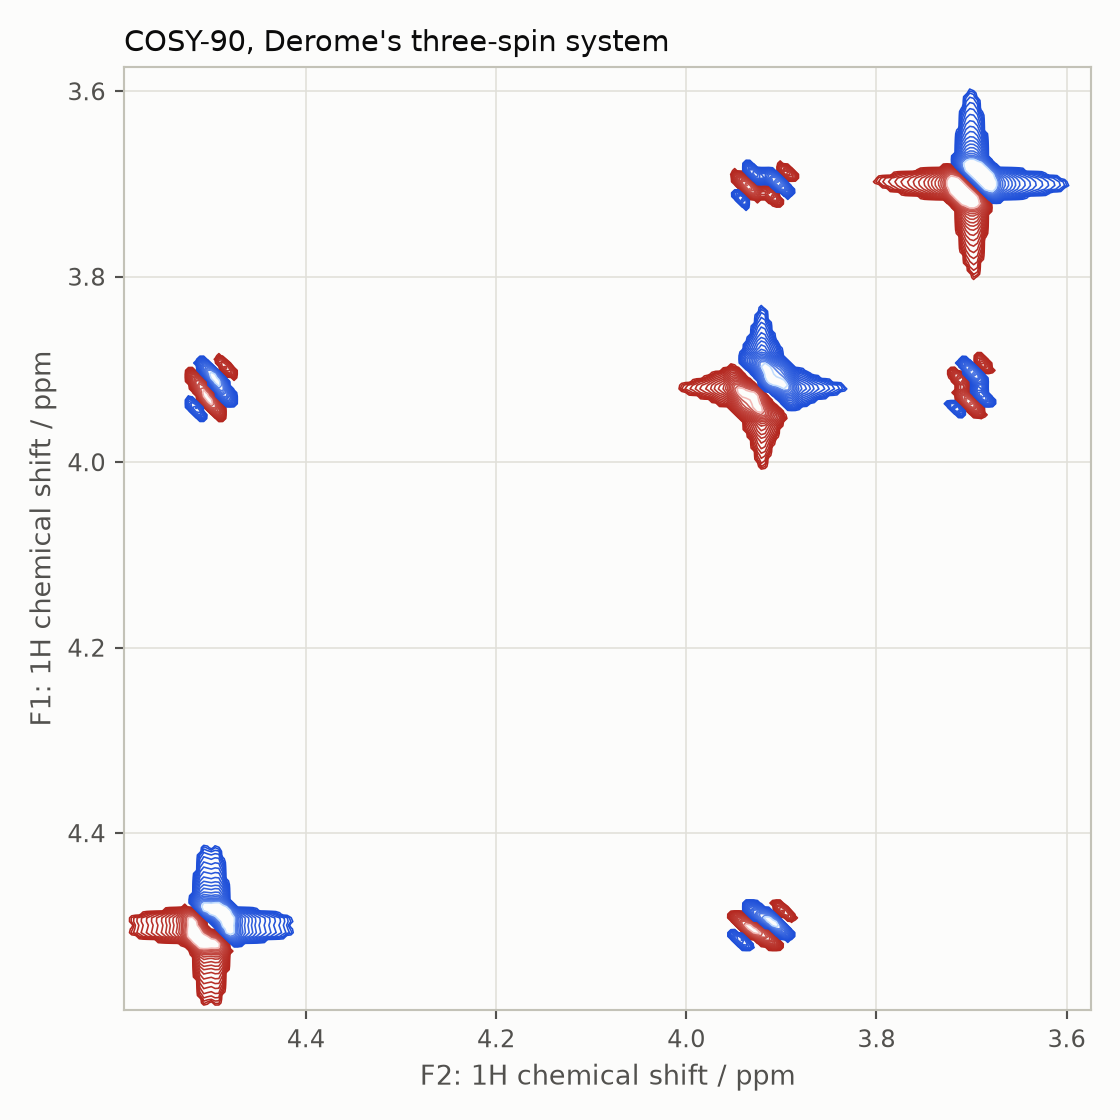

In [2]:
from spynach.plotting import plot_2d

fid_apod = spynach.apodisation(fid, [("sqcos",), ("sqcos",)])
cosy_spectrum = np.fft.fftshift(np.fft.fft2(fid_apod, pars["zerofill"]))
plot_2d(
    spin_system_derome,
    cosy_spectrum.real,
    pars,
    ncont=20,
    delta=(0.1, 0.5, 0.1, 0.5),
    k=2,
    ncol=256,
    m=6,
    signs="both",
    title="COSY-90, Derome's three-spin system",
)

The diagonal carries the three multiplets; the cross peaks connect the
coupled pairs, with the antiphase fine structure of a phase-sensitive
COSY.

## Decoupling, homospoil, dead time

`decouple(spin_system, L, rho, spins)` is Spinach's analytical decoupling: every
basis state that involves the named spins is removed from the dynamics by
zeroing its rows and columns of `L` and its entries of `rho`.
`acquire` applies it through `parameters["decouple"]`, so a heteronuclear
doublet collapses to a singlet; `parameters["dead_time"]` evolves the
state before acquisition and `parameters["homodec_oper"]`/`["homodec_pwr"]`
add a homodecoupling term. `homospoil(spin_system, rho, "destroy")` kills every
coherence (a gradient pulse), `"keep"` retains zero-quantum ones:

In [3]:
spin_system_hc = spynach.basis(spynach.create({"isotopes": ["1H", "13C"], "magnet": 14.1},
                                {"zeeman": {"scalar": [2.0, 30.0]}, "coupling": {"scalar": [[0, 145.0], [0, 0]]}}),
                  {"formalism": "sphten-liouv", "approximation": "none"})
acq = {"spins": ["1H"], "offset": 1200.0, "sweep": 2000.0, "npoints": 128,
       "rho0": spynach.state(spin_system_hc, "L+", "1H"), "coil": spynach.state(spin_system_hc, "L+", "1H")}
coupled = spynach.liquid(spin_system_hc, spynach.acquire, acq, "nmr")
decoupled = spynach.liquid(spin_system_hc, spynach.acquire, {**acq, "decouple": ["13C"]}, "nmr")
t = np.arange(128) / 2000.0
omega = spin_system_hc.basefrqs[0] * 2.0e-6 + 2 * np.pi * 1200.0  # 2 ppm shift in the frame of the 1200 Hz offset
print(np.abs(decoupled - decoupled[0] * np.exp(-1j * omega * t)).max())   # a pure singlet

1.1452344039814851e-08


## COSY

`cosy` is the sequence above with the second pulse angle
`parameters["angle"]` (`pi/2` for COSY-90, `pi/4` for COSY-45), one
`sweep` for both dimensions and two `npoints`. Processing: apodise both
dimensions, `fft2`, plot the real part. The first example of this guide is
Spinach's `examples/nmr_liquids/cosy90_derome.m` at 64 points instead of
1024 per dimension.

## NOESY

`noesy` is the States-TPPI experiment of `noesy.m`: four phase
combinations of the second and third pulses, a homospoil and
relaxation-only mixing (or the full Liouvillian with
`parameters["oldschool"]`), and `{"cos": ..., "sin": ...}` FIDs that are
combined after the F1 transform. It needs relaxation, and the thermal
equilibrium as the initial state (`needs=["rho_eq"]`):

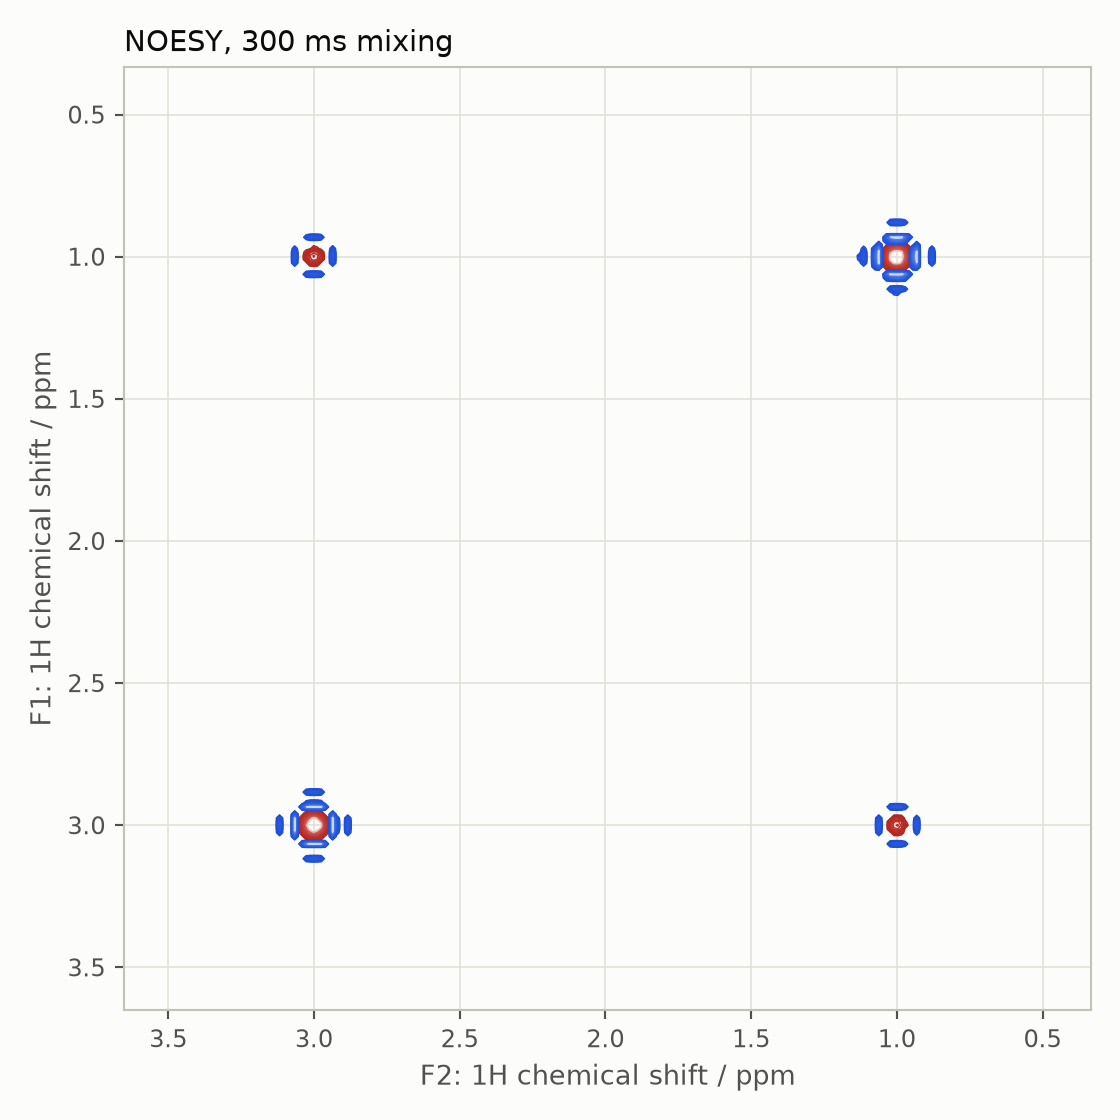

In [4]:
spin_system_pair = spynach.create({"isotopes": ["1H", "1H"], "magnet": 14.1},
                     {"zeeman": {"scalar": [1.0, 3.0]}, "coordinates": [[0, 0, 0], [0, 0, 2.5]],
                      "relaxation": ["redfield"], "equilibrium": "IME", "rlx_keep": "kite",
                      "temperature": 298, "tau_c": [[2e-9]]})
spin_system_pair = spynach.basis(spin_system_pair, {"formalism": "sphten-liouv", "approximation": "none"})
noesy_pars = {"tmix": 0.3, "offset": 1200.0, "sweep": [2000.0, 2000.0], "npoints": [64, 64], "zerofill": [256, 256],
              "spins": ["1H"], "needs": ["rho_eq"], "axis_units": "ppm"}
fid_noesy = spynach.liquid(spin_system_pair, spynach.noesy, noesy_pars, "nmr")
cos = spynach.apodisation(fid_noesy["cos"], [("sqcos",), ("sqcos",)])
sin = spynach.apodisation(fid_noesy["sin"], [("sqcos",), ("sqcos",)])
f1_cos = np.real(np.fft.fftshift(np.fft.fft(cos, 256, axis=0), axes=0))
f1_sin = np.real(np.fft.fftshift(np.fft.fft(sin, 256, axis=0), axes=0))
noesy_spectrum = np.fft.fftshift(np.fft.fft(f1_cos - 1j * f1_sin, 256, axis=1), axes=1)
plot_2d(
    spin_system_pair,
    -noesy_spectrum.real,
    noesy_pars,
    ncont=20,
    delta=(0.05, 0.5, 0.05, 0.5),
    k=2,
    ncol=256,
    m=6,
    signs="both",
    title="NOESY, 300 ms mixing",
)

The protons 2.5 Angstrom apart tumble slowly (`omega tau_c` about 7), so
the cross peaks have the sign of the diagonal, as in large molecules.

## HSQC and isotopomer dilution

`hsqc` is the echo-antiecho experiment of `hsqc.m`: INEPT transfer,
heteronuclear evolution with a refocusing pulse on the decoupled channels
(the `'refocus'` output of `evolution` propagates the second half of
`t1`), coherence selection of the two pathways, back transfer and
decoupled acquisition. `parameters["spins"]` lists the indirect
heteronucleus first, then the detected nucleus; `J` sets the INEPT
delays. Natural-abundance 13C spectra are sums over isotopomers:
`dilute(spin_system, "13C")` returns one subsystem per 13C with every other 13C
removed (`kill_spin`), each of which is simulated separately:

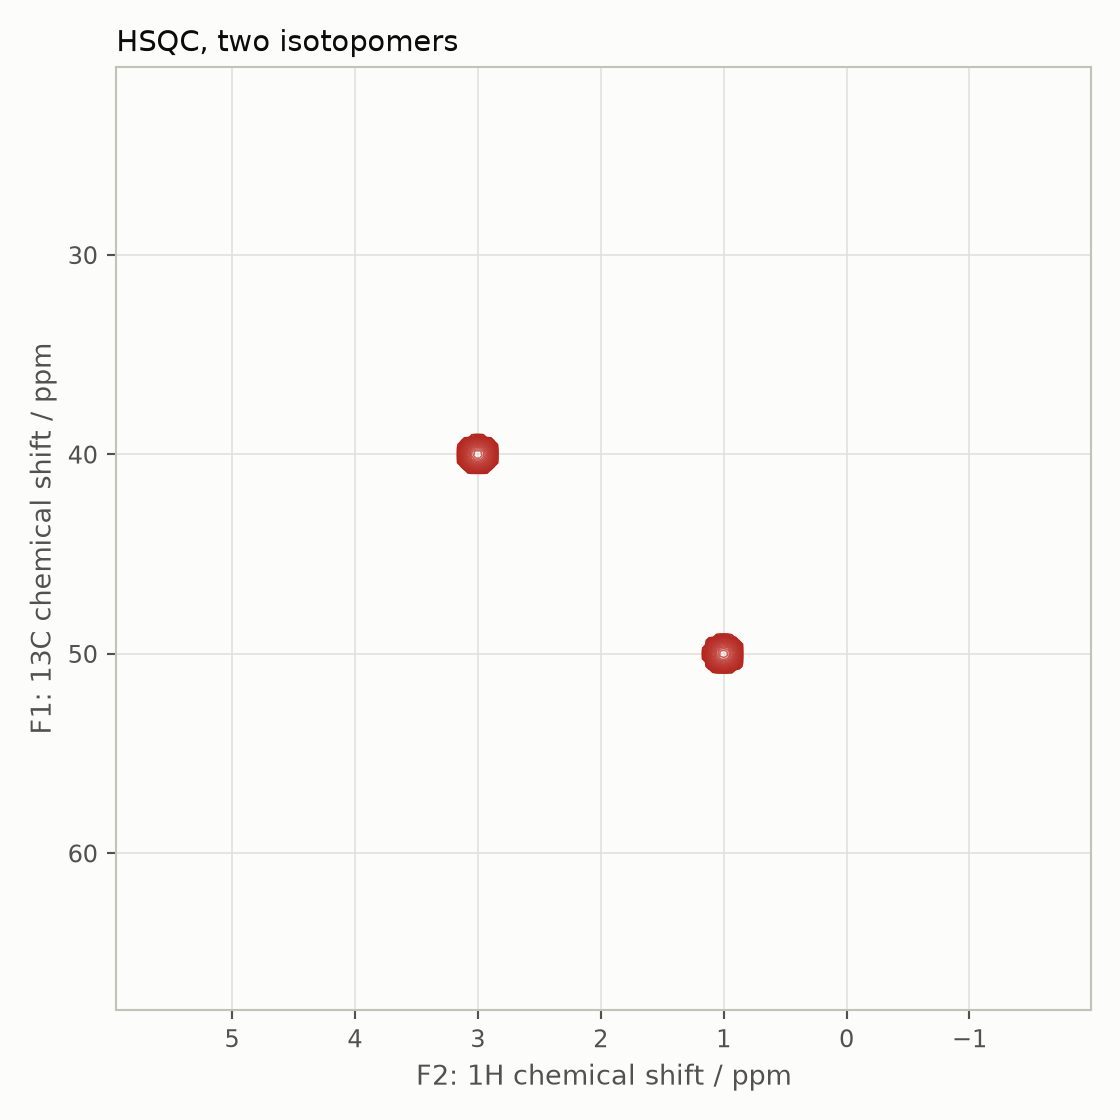

In [5]:
spin_system_sugar = spynach.create({"isotopes": ["1H", "13C", "13C", "1H"], "magnet": 5.9},
                      {"zeeman": {"scalar": [3.0, 40.0, 50.0, 1.0]},
                       "coupling": {"scalar": [[0, 140, 0, 7], [0, 0, 35, 0], [0, 0, 0, 150], [0, 0, 0, 0]]}})
hsqc_pars = {
    "J": 140.0,
    "sweep": [3000.0, 2000.0],
    "offset": [2800.0, 500.0],
    "npoints": [48, 48],
    "zerofill": [256, 256],
    "spins": ["13C", "1H"],
    "decouple_f1": ["1H"],
    "decouple_f2": ["13C"],
    "axis_units": "ppm",
}
hsqc_spectrum = np.zeros((256, 256), dtype=complex)
for spin_system_sub in spynach.dilute(spin_system_sugar, "13C"):
    spin_system_sub = spynach.basis(spin_system_sub, {"formalism": "sphten-liouv", "approximation": "none"})
    fid_hsqc = spynach.liquid(spin_system_sub, spynach.hsqc, hsqc_pars, "nmr")
    pos = np.fft.fftshift(
        np.fft.fft(spynach.apodisation(fid_hsqc["pos"], [("sqcos",), ("sqcos",)]), 256, axis=0), axes=0
    )
    neg = np.fft.fftshift(
        np.fft.fft(spynach.apodisation(fid_hsqc["neg"], [("sqcos",), ("sqcos",)]), 256, axis=0), axes=0
    )
    hsqc_spectrum += np.fft.fftshift(np.fft.fft(pos + np.conj(neg), 256, axis=1), axes=1)
plot_2d(
    spin_system_sugar, hsqc_spectrum.real, hsqc_pars, ncont=20, delta=(0.05, 1.0, 0.05, 1.0), k=2, ncol=256, m=6,
    signs="positive", title="HSQC, two isotopomers",
)

Two cross peaks, one per CH pair, at the carbon shift in F1 and the
proton shift in F2; the carbon-carbon coupling never appears because the
isotopomers contain one 13C each.

## What is not ported yet

- the other sequences of `experiments/nmr_liquids` (`dqf_cosy`, `tocsy`,
  `hmqc`, `hmbc`, `roesy`, `inept`, `dept`, constant-time variants, ...),
  the solid-state and ESR experiments, and real (soft, shaped) pulses;
- `apodisation` windows `bad-z1`/`bad-z2`; `plot_2d` of complex spectra
  side by side; `plot_3d`.

## Checking results against Spinach

`tests/unit/test_sequences.py` checks the window functions, decoupling
(a decoupled doublet becomes a singlet), homospoil, the `'refocus'`
output and `dead_time` against explicit propagation, COSY cross peaks
(present with a coupling, absent without), NOESY cross peaks (sign of the
diagonal for slow tumbling), the HSQC peak position, `dilute`/`kill_spin`,
and the contour levels. `tests/slice/test_seq_parity.py` compares the
COSY, NOESY (both mixing modes) and HSQC FIDs and spectra, the apodisation
helpers, the `'refocus'` output, `acquire` with dead time, homospoil and
decoupling with Spinach 2.13 fixtures (FR-007 in
`porting/FIXTURE_REQUESTS.md`); those tests skip while the fixtures are
absent. Measured agreement (largest elementwise difference relative to
the largest element):

| stage | difference from Spinach |
|---|---|
| COSY FID (64 x 64) and spectrum | 1e-13, 5e-14 |
| `apodisation` (all tested windows) | 2e-14 |
| `'refocus'` output, `acquire` with `dead_time`, `homospoil` | 2e-14 |
| NOESY cos/sin FIDs, both mixing modes | 1e-14 |
| HSQC pos/neg FIDs per isotopomer and the summed spectrum | 8e-14 |
| `decouple` of a Liouvillian and a state | 0 |